# 17 â€” Anatomy-aware framework: Phases 1, 2, and 3

This notebook implements the first three stages of the proposed anatomy-aware, self-correcting reconstruction
framework. Each later stage executes only after the preceding frozen acceptance checks pass.

Phase 1 has four objectives:

1. freeze the exact development cohort, labels, preprocessing, checkpoint, and seed;
2. prove that the official test split remains unopened;
3. reproduce the saved MONAI 3D U-Net validation result on its original reference-mask-defined head crop;
4. evaluate the same frozen checkpoint on a **CT-only foreground crop** to quantify the oracle-crop limitation.

The five validation cases were previously used for checkpoint selection. Results are therefore development
metrics, not independent test estimates. Nothing in this notebook trains a model or changes a checkpoint.

In [1]:
import hashlib
import json
import os
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    raise RuntimeError("Run this notebook from the F:/csstdy project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.benchmark.brain_skull import (
    INPUT_CHANNELS,
    evaluate_model,
    load_or_create_inventory,
    make_model,
    predict_case,
    prepare_inventory,
    sha256_file,
)
from src.dataset.preprocessing import ct_foreground_bbox

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"
INVENTORY_PATH = PROJECT_ROOT / "outputs" / "brain_skull_benchmark" / "development_inventory.json"
BASELINE_REPORT_PATH = PROJECT_ROOT / "outputs" / "brain_skull_benchmark" / "unet3d" / "benchmark_report.json"
CHECKPOINT_PATH = PROJECT_ROOT / "outputs" / "brain_skull_benchmark" / "unet3d" / "best.pt"
ORACLE_CACHE_ROOT = PROJECT_ROOT / "data" / "cache" / "brain_skull_benchmark"
OUTPUT_ROOT = PROJECT_ROOT / "outputs" / "anatomy_aware_framework" / "phase1"
CT_CACHE_ROOT = OUTPUT_ROOT / "ct_only_cache"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
CT_CACHE_ROOT.mkdir(parents=True, exist_ok=True)

SEED = 42
ROI = 96
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is required to reproduce the saved GPU benchmark")
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATASET_ROOT)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Dataset: F:\csstdy\Totalsegmentator_dataset_v201


## 1. Freeze the Phase 1 experiment contract

The inventory function enumerates only official `train` and `val` cases. It never resolves a test-case path.
The new contract records the prior model contract and checkpoint hashes instead of overwriting either file.

The CT-only crop uses the already configured preprocessing rule: voxels above âˆ’900 HU with a ten-voxel
margin. Crop selection sees the CT only. Reference masks are loaded afterward solely for scoring.

In [2]:
inventory = load_or_create_inventory(DATASET_ROOT, MANIFEST_PATH, INVENTORY_PATH)
assert inventory["test_split_accessed"] is False
assert inventory["selected_counts"] == {"train": 98, "val": 5}
baseline_report = json.loads(BASELINE_REPORT_PATH.read_text(encoding="utf-8"))
assert baseline_report["test_split_accessed"] is False
assert sha256_file(CHECKPOINT_PATH) == baseline_report["best_checkpoint_sha256"]

dataset_config = yaml.safe_load((PROJECT_ROOT / "configs" / "dataset.yaml").read_text(encoding="utf-8"))
crop_config = dataset_config["preprocessing"]["foreground_crop"]
ct_crop_threshold_hu = float(crop_config["threshold_hu"])
ct_crop_margin = tuple(int(value) for value in crop_config["margin_voxels"])
val_case_ids = [item["case_id"] for item in inventory["cases"] if item["split"] == "val"]

contract = {
    "schema_version": 1,
    "phase": "phase1_baseline_reproduction",
    "framework": "anatomy_aware_self_correcting_geometry_adaptive",
    "dataset_manifest_sha256": sha256_file(MANIFEST_PATH),
    "development_inventory_sha256": sha256_file(INVENTORY_PATH),
    "selected_counts": inventory["selected_counts"],
    "validation_case_ids": val_case_ids,
    "labels": {"0": "background", "1": "brain", "2": "skull"},
    "overlap_policy": "skull wins",
    "model": "MONAI compact residual 3D U-Net from Notebook 15",
    "checkpoint": str(CHECKPOINT_PATH),
    "checkpoint_sha256": sha256_file(CHECKPOINT_PATH),
    "checkpoint_contract_sha256": baseline_report["contract_sha256"],
    "selected_epoch": baseline_report["selected_epoch"],
    "roi": [ROI, ROI, ROI],
    "input_channels": list(INPUT_CHANNELS),
    "random_seed": SEED,
    "crop_modes": {
        "oracle": "brain-or-skull reference bounding box plus 16 voxels; reproduction only",
        "ct_only": {
            "method": "existing ct_foreground_bbox",
            "threshold_hu": ct_crop_threshold_hu,
            "margin_voxels": list(ct_crop_margin),
        },
    },
    "official_test_split_accessed": False,
    "training_performed": False,
    "limitations": [
        "Five validation cases were used for checkpoint selection.",
        "Oracle-crop scores are not CT-only deployment estimates.",
        "No calibration or rescue threshold is selected in Phase 1.",
    ],
}
contract_path = OUTPUT_ROOT / "frozen_contract.json"
contract_path.write_text(json.dumps(contract, indent=2) + "\n", encoding="utf-8")
print("Frozen contract:", contract_path)
display(pd.DataFrame({"validation_case_id": val_case_ids}))

Frozen contract: F:\csstdy\outputs\anatomy_aware_framework\phase1\frozen_contract.json


,validation_case_id
0,s0346
1,s0792
2,s0874
3,s1161
4,s1260


## 2. Reproduce the saved oracle-ROI baseline

The best checkpoint is deserialized with `weights_only=True`, its embedded contract is verified, and it is
evaluated with the same sliding-window function used in Notebook 15. A tight numerical tolerance permits
harmless floating-point variation while preventing a different result from being called a reproduction.

In [3]:
prepared = prepare_inventory(DATASET_ROOT, inventory, ORACLE_CACHE_ROOT)
assert all(item["split"] in {"train", "val"} for item in prepared)
oracle_val = [item for item in prepared if item["split"] == "val"]
assert [item["case_id"] for item in oracle_val] == val_case_ids

checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
assert checkpoint["contract_sha256"] == baseline_report["contract_sha256"]
model = make_model("unet3d").to(DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()

torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()
oracle_result = evaluate_model(
    model, oracle_val, device=DEVICE, roi=ROI, include_hd95=True,
)
oracle_seconds = time.perf_counter() - started
oracle_peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

tolerance = 5e-5
for organ in ("brain", "skull"):
    expected = baseline_report["validation"]["mean_dice"][organ]
    observed = oracle_result["mean_dice"][organ]
    if abs(observed - expected) > tolerance:
        raise AssertionError(f"{organ} Dice did not reproduce: {observed} vs {expected}")

oracle_table = pd.DataFrame([
    {
        "crop": "oracle_reference_mask",
        "organ": organ,
        "mean_dice": oracle_result["mean_dice"][organ],
        "mean_hd95_mm": oracle_result["mean_hd95_mm"][organ],
        "five_case_inference_seconds": oracle_seconds,
        "peak_gpu_memory_mb": oracle_peak_mb,
    }
    for organ in ("brain", "skull")
])
display(oracle_table.style.format(precision=4))

F:\csstdy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


F:\csstdy\.venv\Lib\site-packages\torch\jit\_script.py:1643: FutureWarning: `torch.jit.interface` is deprecated. Please use `torch.compile` instead.
  warnings.warn(


,crop,organ,mean_dice,mean_hd95_mm,five_case_inference_seconds,peak_gpu_memory_mb
0,oracle_reference_mask,brain,0.9649,62.3839,5.5133,120.7158
1,oracle_reference_mask,skull,0.9313,9.9870,5.5133,120.7158


## 3. Create the CT-only evaluation crop

Crop selection is completed before either reference mask is opened. The masks are then cropped with the
already frozen CT-derived box for evaluation. Source data are never modified. The cache is local to Phase 1
and records the original-space crop origin and affine.

In [4]:
def atomic_save_array(path: Path, array: np.ndarray) -> None:
    temporary = path.with_suffix(".tmp.npy")
    np.save(temporary, array)
    os.replace(temporary, path)


def prepare_ct_only_case(record: dict) -> tuple[dict, dict]:
    if record["split"] != "val":
        raise ValueError("Phase 1 CT-only cache accepts validation records only")
    case_id = record["case_id"]
    case_root = DATASET_ROOT / case_id
    ct_image = nib.load(str(case_root / "ct.nii.gz"))
    hu = np.asarray(ct_image.dataobj, dtype=np.float32)
    if hu.ndim != 3 or not np.isfinite(hu).all():
        raise ValueError(f"Invalid CT: {case_id}")

    # This is the complete crop decision. No label has been read above this line.
    bbox = ct_foreground_bbox(
        hu, threshold_hu=ct_crop_threshold_hu, margin_voxels=ct_crop_margin
    )
    slices = tuple(slice(start, end) for start, end in bbox)
    starts = np.asarray([start for start, _ in bbox], dtype=np.float64)
    crop_affine = np.asarray(ct_image.affine, dtype=np.float64).copy()
    crop_affine[:3, 3] = (ct_image.affine @ np.asarray([*starts, 1.0]))[:3]

    brain_image = nib.load(str(case_root / "segmentations" / "brain.nii.gz"))
    skull_image = nib.load(str(case_root / "segmentations" / "skull.nii.gz"))
    if (
        brain_image.shape != ct_image.shape
        or skull_image.shape != ct_image.shape
        or not np.allclose(brain_image.affine, ct_image.affine, atol=1e-3, rtol=0)
        or not np.allclose(skull_image.affine, ct_image.affine, atol=1e-3, rtol=0)
    ):
        raise ValueError(f"CT/mask geometry mismatch: {case_id}")
    brain = np.asarray(brain_image.dataobj) > 0
    skull = np.asarray(skull_image.dataobj) > 0
    label_full = np.zeros(ct_image.shape, dtype=np.uint8)
    label_full[brain] = 1
    label_full[skull] = 2
    label = label_full[slices]
    crop_hu = hu[slices]
    image = np.stack([
        np.clip((crop_hu + 100.0) / 300.0, 0.0, 1.0),
        np.clip((crop_hu + 300.0) / 1800.0, 0.0, 1.0),
    ], axis=0).astype(np.float16)

    image_path = CT_CACHE_ROOT / f"{case_id}_image.npy"
    label_path = CT_CACHE_ROOT / f"{case_id}_label.npy"
    atomic_save_array(image_path, image)
    atomic_save_array(label_path, label)
    retained = {
        "brain": int(np.count_nonzero(label == 1)) / int(np.count_nonzero(label_full == 1)),
        "skull": int(np.count_nonzero(label == 2)) / int(np.count_nonzero(label_full == 2)),
    }
    metadata = {
        "case_id": case_id,
        "split": "val",
        "image_path": str(image_path),
        "label_path": str(label_path),
        "shape": list(label.shape),
        "crop_start": starts.astype(int).tolist(),
        "crop_bbox": [list(item) for item in bbox],
        "ct_affine": crop_affine.tolist(),
        "input_channels": list(INPUT_CHANNELS),
        "source_ct_sha256": sha256_file(case_root / "ct.nii.gz"),
        "crop_selected_without_labels": True,
    }
    (CT_CACHE_ROOT / f"{case_id}_meta.json").write_text(
        json.dumps(metadata, indent=2) + "\n", encoding="utf-8"
    )
    return metadata, retained


ct_only_val, retention_rows = [], []
inventory_by_id = {item["case_id"]: item for item in inventory["cases"]}
for case_id in val_case_ids:
    metadata, retained = prepare_ct_only_case(inventory_by_id[case_id])
    ct_only_val.append(metadata)
    retention_rows.append({"case_id": case_id, **retained, "shape": metadata["shape"]})
retention = pd.DataFrame(retention_rows)
display(retention)
if not np.allclose(retention[["brain", "skull"]].to_numpy(), 1.0):
    raise AssertionError("CT-only crop removed reference brain/skull voxels")

,case_id,brain,skull,shape
0,s0346,1.0,1.0,"[215, 215, 241]"
1,s0792,1.0,1.0,"[125, 152, 109]"
2,s0874,1.0,1.0,"[142, 184, 247]"
3,s1161,1.0,1.0,"[313, 313, 544]"
4,s1260,1.0,1.0,"[135, 135, 113]"


## 4. Evaluate oracle versus CT-only crop

Only the crop changes. Checkpoint, network, two CT windows, sliding-window ROI, label semantics and metrics
remain fixed. This isolates whether the original oracle crop inflated or stabilized the reported baseline.

In [5]:
torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()
ct_result = evaluate_model(
    model, ct_only_val, device=DEVICE, roi=ROI, include_hd95=True,
)
ct_seconds = time.perf_counter() - started
ct_peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)

rows = []
for organ in ("brain", "skull"):
    rows.extend([
        {
            "crop": "oracle_reference_mask",
            "organ": organ,
            "mean_dice": oracle_result["mean_dice"][organ],
            "mean_hd95_mm": oracle_result["mean_hd95_mm"][organ],
            "five_case_inference_seconds": oracle_seconds,
            "peak_gpu_memory_mb": oracle_peak_mb,
        },
        {
            "crop": "ct_only_foreground",
            "organ": organ,
            "mean_dice": ct_result["mean_dice"][organ],
            "mean_hd95_mm": ct_result["mean_hd95_mm"][organ],
            "five_case_inference_seconds": ct_seconds,
            "peak_gpu_memory_mb": ct_peak_mb,
        },
    ])
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT_ROOT / "oracle_vs_ct_only.csv", index=False)
display(comparison.style.format(precision=4))

by_case_rows = []
oracle_cases = {item["case_id"]: item for item in oracle_result["cases"]}
ct_cases = {item["case_id"]: item for item in ct_result["cases"]}
for case_id in val_case_ids:
    for crop_name, source in (("oracle_reference_mask", oracle_cases), ("ct_only_foreground", ct_cases)):
        for organ in ("brain", "skull"):
            by_case_rows.append({
                "case_id": case_id,
                "crop": crop_name,
                "organ": organ,
                "dice": source[case_id]["dice"][organ],
                "hd95_mm": source[case_id]["hd95_mm"][organ],
            })
per_case = pd.DataFrame(by_case_rows)
per_case.to_csv(OUTPUT_ROOT / "per_case_metrics.csv", index=False)
display(per_case.pivot_table(index=["case_id", "organ"], columns="crop", values="dice"))

,crop,organ,mean_dice,mean_hd95_mm,five_case_inference_seconds,peak_gpu_memory_mb
0,oracle_reference_mask,brain,0.9649,62.3839,5.5133,120.7158
1,ct_only_foreground,brain,0.6780,215.6314,34.8858,1478.5933
2,oracle_reference_mask,skull,0.9313,9.9870,5.5133,120.7158
3,ct_only_foreground,skull,0.6450,186.9927,34.8858,1478.5933


crop           ct_only_foreground  oracle_reference_mask
case_id organ                                           
s0346   brain            0.744226               0.965109
        skull            0.515669               0.899978
s0792   brain            0.984257               0.984955
        skull            0.954780               0.954997
s0874   brain            0.600125               0.907570
        skull            0.686607               0.932881
s1161   brain            0.072332               0.977760
        skull            0.122623               0.922043
s1260   brain            0.988938               0.988954
        skull            0.945245               0.946581

## 5. Qualitative alignment check

Red is the reference contour and cyan is the prediction. This panel is a diagnostic illustration; the
quantitative result is computed over all five validation volumes.

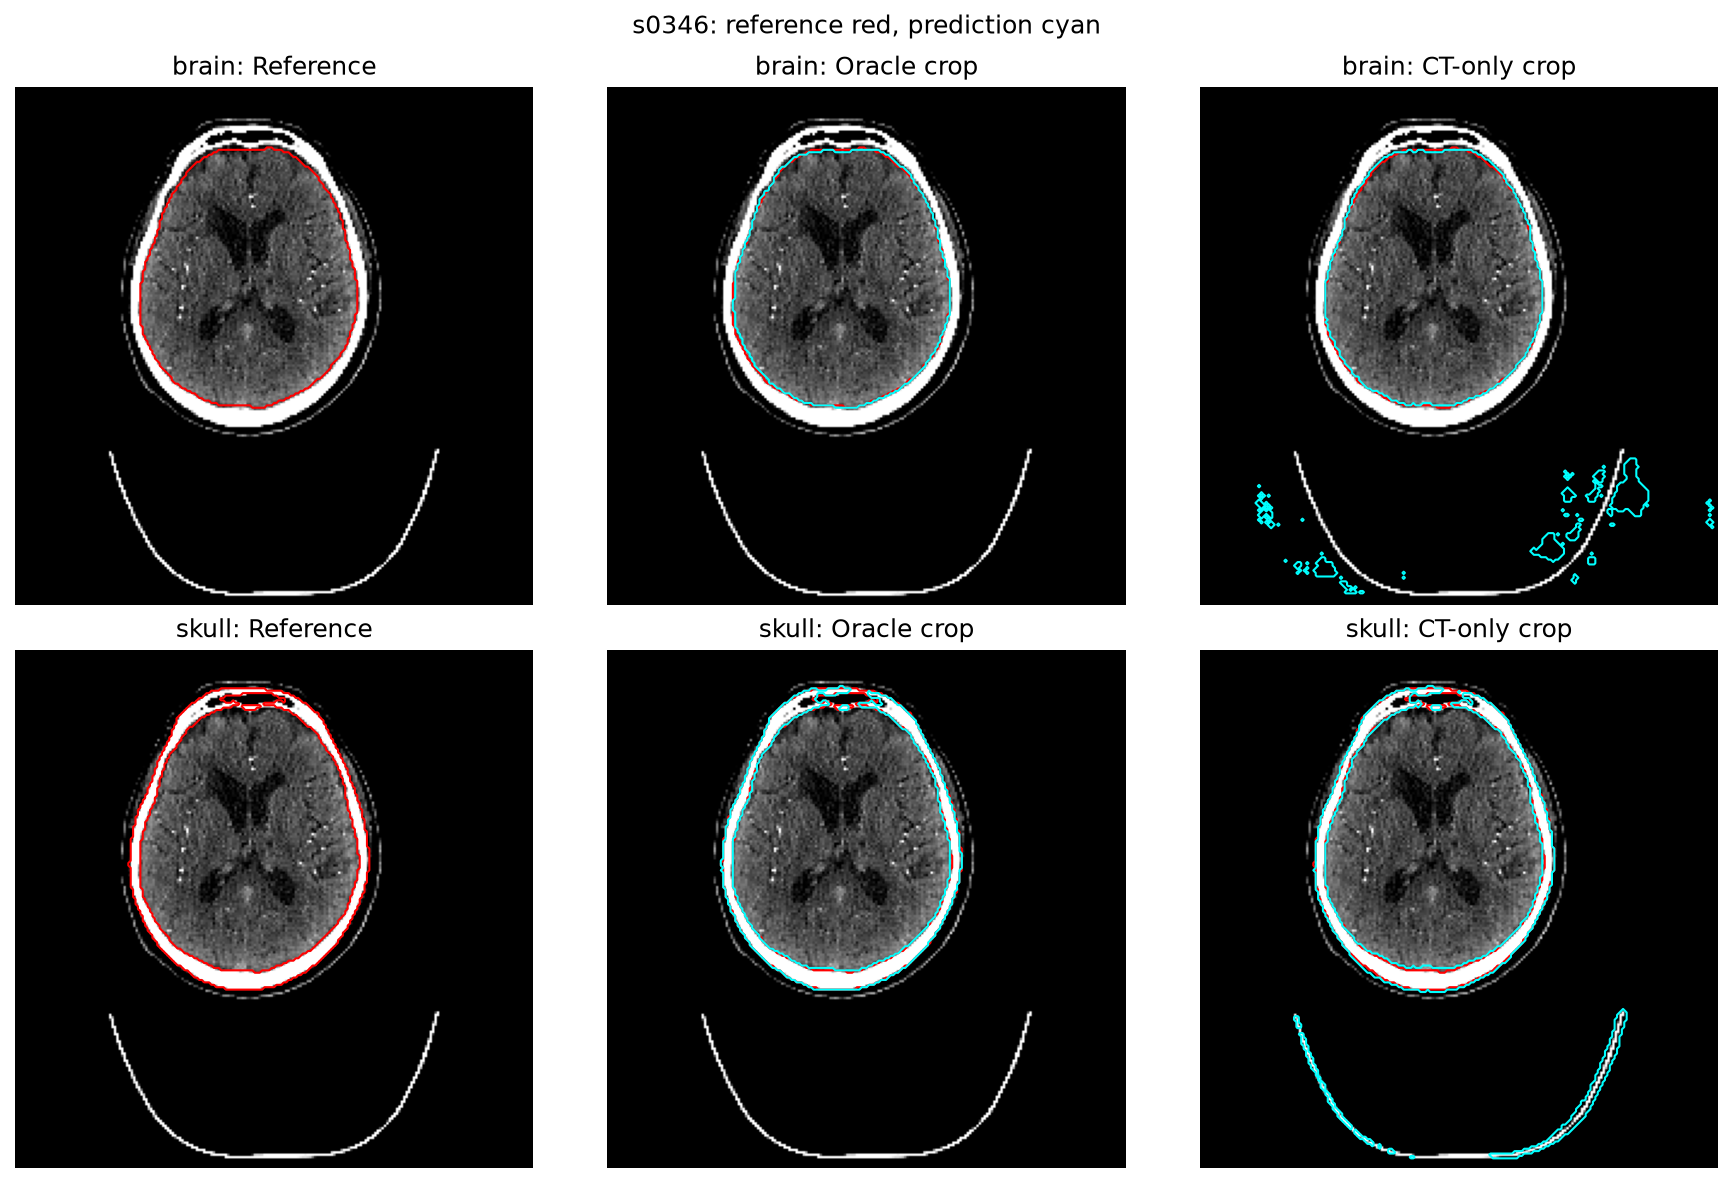

In [6]:
example_id = "s0346"
oracle_record = next(item for item in oracle_val if item["case_id"] == example_id)
ct_record = next(item for item in ct_only_val if item["case_id"] == example_id)
oracle_prediction = predict_case(model, oracle_record, device=DEVICE, roi=ROI)
ct_prediction = predict_case(model, ct_record, device=DEVICE, roi=ROI)
ct_image = np.load(ct_record["image_path"], mmap_mode="r")[0]
ct_label = np.load(ct_record["label_path"], mmap_mode="r")

# Embed the oracle prediction in CT-only crop coordinates for a matched visual plane.
embedded_oracle = np.zeros_like(ct_label)
oracle_start = np.asarray(oracle_record["crop_start"], dtype=int)
ct_start = np.asarray(ct_record["crop_start"], dtype=int)
offset = oracle_start - ct_start
target_slices, source_slices = [], []
for axis in range(3):
    target_start = max(0, int(offset[axis]))
    target_end = min(ct_label.shape[axis], int(offset[axis]) + oracle_prediction.shape[axis])
    source_start = max(0, -int(offset[axis]))
    source_end = source_start + max(0, target_end - target_start)
    target_slices.append(slice(target_start, target_end))
    source_slices.append(slice(source_start, source_end))
embedded_oracle[tuple(target_slices)] = oracle_prediction[tuple(source_slices)]

z = int(np.rint(np.argwhere(ct_label == 1)[:, 2].mean()))
fig, axes = plt.subplots(2, 3, figsize=(12, 8), dpi=150)
panels = [
    ("Reference", ct_label),
    ("Oracle crop", embedded_oracle),
    ("CT-only crop", ct_prediction),
]
for row, (class_id, organ) in enumerate(((1, "brain"), (2, "skull"))):
    for column, (title, labels) in enumerate(panels):
        axis = axes[row, column]
        axis.imshow(ct_image[:, :, z].T, cmap="gray", vmin=0.35, vmax=0.75, origin="lower")
        axis.contour((ct_label[:, :, z] == class_id).T, levels=[0.5], colors="red", linewidths=1.0)
        if title != "Reference":
            axis.contour((labels[:, :, z] == class_id).T, levels=[0.5], colors="cyan", linewidths=1.0)
        axis.set_title(f"{organ}: {title}")
        axis.axis("off")
fig.suptitle(f"{example_id}: reference red, prediction cyan")
fig.tight_layout()
figure_path = OUTPUT_ROOT / "oracle_vs_ct_only_s0346.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

## 6. Phase 1 acceptance report

Phase 1 passes only if the prior baseline is reproduced, the CT-only crop retains all target voxels for these
five cases, checkpoint/data hashes match, and no test path was opened. A lower CT-only score is a valid result,
not a failure to be hidden. Phase 2 must not start by silently changing this contract.

In [7]:
acceptance = {
    "official_test_split_unopened": inventory["test_split_accessed"] is False,
    "development_counts_exact": inventory["selected_counts"] == {"train": 98, "val": 5},
    "checkpoint_hash_verified": sha256_file(CHECKPOINT_PATH) == baseline_report["best_checkpoint_sha256"],
    "checkpoint_contract_verified": checkpoint["contract_sha256"] == baseline_report["contract_sha256"],
    "oracle_brain_dice_reproduced": abs(
        oracle_result["mean_dice"]["brain"] - baseline_report["validation"]["mean_dice"]["brain"]
    ) <= tolerance,
    "oracle_skull_dice_reproduced": abs(
        oracle_result["mean_dice"]["skull"] - baseline_report["validation"]["mean_dice"]["skull"]
    ) <= tolerance,
    "ct_only_crop_retained_all_reference_voxels": bool(
        np.allclose(retention[["brain", "skull"]].to_numpy(), 1.0)
    ),
    "training_performed": False,
}
passed = all(value is True for key, value in acceptance.items() if key != "training_performed") and acceptance["training_performed"] is False
phase_report = {
    "schema_version": 1,
    "phase": 1,
    "status": "passed" if passed else "failed",
    "contract_path": str(contract_path),
    "contract_sha256": sha256_file(contract_path),
    "acceptance": acceptance,
    "oracle_result": oracle_result,
    "ct_only_result": ct_result,
    "runtime": {
        "oracle_five_cases_seconds": oracle_seconds,
        "ct_only_five_cases_seconds": ct_seconds,
        "oracle_peak_gpu_memory_mb": oracle_peak_mb,
        "ct_only_peak_gpu_memory_mb": ct_peak_mb,
    },
    "outputs": {
        "comparison_csv": str(OUTPUT_ROOT / "oracle_vs_ct_only.csv"),
        "per_case_csv": str(OUTPUT_ROOT / "per_case_metrics.csv"),
        "visual_qa": str(figure_path),
    },
    "official_test_split_accessed": False,
    "next_phase": "multi-task segmentation plus spacing-aware signed distance fields",
}
report_path = OUTPUT_ROOT / "phase1_report.json"
report_path.write_text(json.dumps(phase_report, indent=2) + "\n", encoding="utf-8")
display(pd.DataFrame(acceptance.items(), columns=["check", "value"]))
print("Phase 1:", phase_report["status"])
print("Report:", report_path)
if not passed:
    raise RuntimeError("Phase 1 acceptance failed; do not proceed to Phase 2")

del model
torch.cuda.empty_cache()

,check,value
0,official_test_split_unopened,True
1,development_counts_exact,True
2,checkpoint_hash_verified,True
3,checkpoint_contract_verified,True
4,oracle_brain_dice_reproduced,True
5,oracle_skull_dice_reproduced,True
6,ct_only_crop_retained_all_reference_voxels,True
7,training_performed,False


Phase 1: passed
Report: F:\csstdy\outputs\anatomy_aware_framework\phase1\phase1_report.json


# Phase 2 â€” Multi-task brain/skull segmentation with signed-distance geometry

Phase 1 passed, so the same notebook now advances to Phase 2. A shared MONAI 3D U-Net representation feeds
two independent heads:

- **segmentation head:** background, brain, and skull logits;
- **geometry head:** normalized physical signed-distance fields for brain and skull.

The SDF sign is positive inside each structure and negative outside. Distances are calculated in millimetres,
truncated at Â±25 mm, and normalized to `[-1,1]`. The SDF loss weight increases in three predeclared stages.
No anatomy constraint, uncertainty threshold, rescue network, or test data is introduced in this phase.

In [8]:
from src.dataset.brain_skull_multitask import prepare_ct_only_multitask_inventory
from src.training.anatomy_phase2 import (
    build_phase2_model,
    predict_multitask,
    sha256_file as phase2_sha256_file,
    train_phase2,
)

PHASE2_CONFIG_PATH = PROJECT_ROOT / "configs" / "anatomy_aware_v1.yaml"
phase2_config = yaml.safe_load(PHASE2_CONFIG_PATH.read_text(encoding="utf-8"))
PHASE2_ROOT = PROJECT_ROOT / phase2_config["outputs"]["root"]
PHASE2_CACHE = PROJECT_ROOT / phase2_config["outputs"]["cache"]
PHASE2_ROOT.mkdir(parents=True, exist_ok=True)
PHASE2_CACHE.mkdir(parents=True, exist_ok=True)
if not passed:
    raise RuntimeError("Phase 2 is blocked because Phase 1 did not pass")
if phase2_config["locks"]["official_test_locked"] is not True:
    raise RuntimeError("Phase 2 configuration must keep the official test split locked")
print("Phase 2 config:", PHASE2_CONFIG_PATH)
print("Phase 1 contract SHA256:", sha256_file(contract_path))

Phase 2 config: F:\csstdy\configs\anatomy_aware_v1.yaml
Phase 1 contract SHA256: fe0dd108e76f1cfeeb60f2809eef2e2845fb53f7d6af9c696bdd2e54cc4c8405


## 7. Cache CT-only inputs and physical SDF targets

All 98 training and five validation cases use the same CT-only crop rule measured in Phase 1. The crop is
selected before loading labels. SDFs are cached as two float16 channels only after being calculated using the
physical voxel spacing from each CT affine. Official test cases are rejected by the cache function.

In [9]:
data_cfg = phase2_config["data"]
sdf_cfg = phase2_config["sdf"]

def cache_progress(index, total, case_id):
    if index == 1 or index % 10 == 0 or index == total:
        print(f"Phase 2 cache {index}/{total}: {case_id}", flush=True)

phase2_records = prepare_ct_only_multitask_inventory(
    DATASET_ROOT,
    inventory["cases"],
    PHASE2_CACHE,
    threshold_hu=float(data_cfg["crop"]["threshold_hu"]),
    margin_voxels=tuple(int(value) for value in data_cfg["crop"]["margin_voxels"]),
    max_distance_mm=float(sdf_cfg["max_distance_mm"]),
    workers=int(data_cfg["cache_workers"]),
    progress=cache_progress,
)
phase2_train = [item for item in phase2_records if item["split"] == "train"]
phase2_val = [item for item in phase2_records if item["split"] == "val"]
assert len(phase2_train) == 98 and len(phase2_val) == 5
assert all(item["crop_selected_without_labels"] for item in phase2_records)
assert all(
    np.isclose(item["reference_retention"][organ], 1.0)
    for item in phase2_records for organ in ("brain", "skull")
)

cache_table = pd.DataFrame([
    {
        "case_id": item["case_id"],
        "split": item["split"],
        "shape": "Ã—".join(str(value) for value in item["shape"]),
        "spacing_mm": "Ã—".join(f"{value:.2f}" for value in item["spacing_mm"]),
        "brain_voxels": item["label_voxels"]["1"],
        "skull_voxels": item["label_voxels"]["2"],
    }
    for item in phase2_records
])
cache_table.to_csv(PHASE2_ROOT / "cached_case_inventory.csv", index=False)
display(cache_table.groupby("split").size().rename("cases").to_frame())

Phase 2 cache 1/103: s0101


Phase 2 cache 10/103: s0224


Phase 2 cache 20/103: s0412


Phase 2 cache 30/103: s0575


Phase 2 cache 40/103: s0713


Phase 2 cache 50/103: s0855


... (3 outputs left out)

Phase 2 cache 90/103: s1231


Phase 2 cache 100/103: s0792


Phase 2 cache 103/103: s1161


,cases
split,
train,98
val,5


## 8. SDF sanity check

White/red regions are inside the selected structure, blue regions are outside, and zero is the boundary.
This check prevents a reversed sign or channel order from silently entering training.

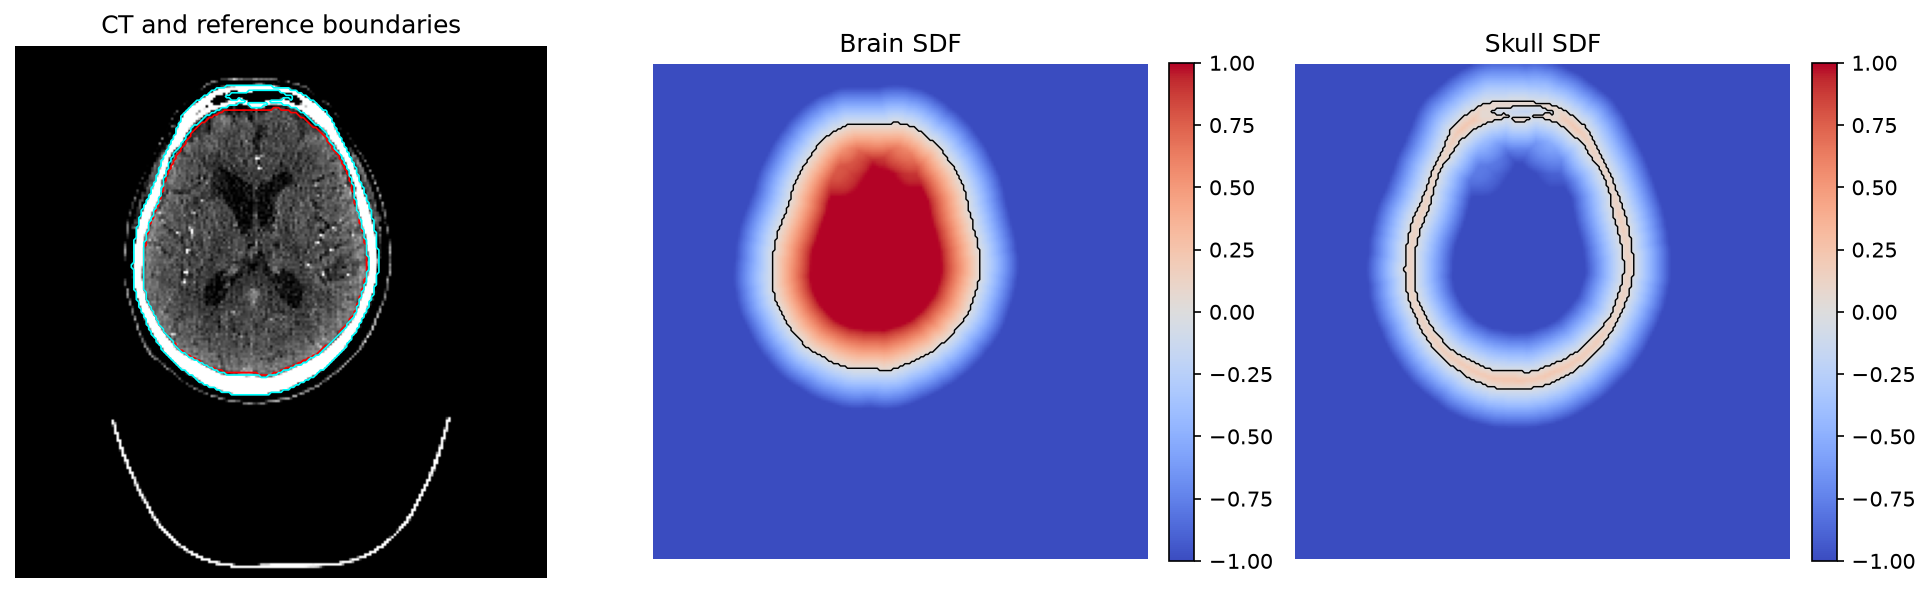

In [10]:
sdf_example = next(item for item in phase2_val if item["case_id"] == "s0346")
sdf_label = np.load(sdf_example["label_path"], mmap_mode="r")
sdf_target = np.load(sdf_example["sdf_path"], mmap_mode="r")
sdf_image = np.load(sdf_example["image_path"], mmap_mode="r")[0]
z_sdf = int(np.rint(np.argwhere(sdf_label == 1)[:, 2].mean()))
assert sdf_target.shape == (2, *sdf_label.shape)
assert np.isfinite(sdf_target).all() and sdf_target.min() >= -1 and sdf_target.max() <= 1
assert float(np.mean(sdf_target[0][sdf_label == 1])) > 0
assert float(np.mean(sdf_target[1][sdf_label == 2])) > 0

fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=150)
axes[0].imshow(sdf_image[:, :, z_sdf].T, cmap="gray", origin="lower", vmin=0.35, vmax=0.75)
axes[0].contour((sdf_label[:, :, z_sdf] == 1).T, levels=[0.5], colors="red", linewidths=0.8)
axes[0].contour((sdf_label[:, :, z_sdf] == 2).T, levels=[0.5], colors="cyan", linewidths=0.8)
axes[0].set_title("CT and reference boundaries")
for axis, channel, title in ((axes[1], 0, "Brain SDF"), (axes[2], 1, "Skull SDF")):
    shown = axis.imshow(sdf_target[channel, :, :, z_sdf].T, cmap="coolwarm", origin="lower", vmin=-1, vmax=1)
    axis.contour(sdf_target[channel, :, :, z_sdf].T, levels=[0], colors="black", linewidths=0.7)
    axis.set_title(title)
    fig.colorbar(shown, ax=axis, fraction=0.046, pad=0.04)
for axis in axes:
    axis.axis("off")
fig.tight_layout()
sdf_figure_path = PHASE2_ROOT / "sdf_target_sanity_s0346.png"
fig.savefig(sdf_figure_path, bbox_inches="tight")
plt.show()

## 9. Train or resume the Phase 2 model

Training uses one deterministic `96Â³` patch per training case and epoch. Eighty percent of patches are centred
on brain or skull; twenty percent sample CT foreground outside both labels so the network learns the context
that caused Phase 1's table/body false positives. Validation occurs every five epochs on the full CT-only crop.

`last.pt` supports exact task-contract resume and `best.pt` is selected only by validation macro Dice.

In [11]:
phase2_report = train_phase2(
    phase2_records,
    phase2_config,
    PHASE2_ROOT,
    phase1_contract_sha256=sha256_file(contract_path),
    config_sha256=sha256_file(PHASE2_CONFIG_PATH),
    progress=lambda message: print(message, flush=True),
)
assert phase2_report["official_test_split_accessed"] is False
print("Selected epoch:", phase2_report["selected_epoch"])
print("Best checkpoint:", phase2_report["best_checkpoint"])
display(pd.DataFrame([
    {
        "organ": organ,
        "Dice": phase2_report["validation"]["mean_dice"][organ],
        "HD95 (mm)": phase2_report["validation"]["mean_hd95_mm"][organ],
        "SDF MAE (normalized)": phase2_report["validation"]["mean_sdf_mae_normalized"][organ],
        "Boundary SDF MAE": phase2_report["validation"]["mean_boundary_sdf_mae_normalized"][organ],
    }
    for organ in ("brain", "skull")
]).style.format(precision=4))

Selected epoch: 25
Best checkpoint: F:\csstdy\outputs\anatomy_aware_framework\phase2\best.pt


,organ,Dice,HD95 (mm),SDF MAE (normalized),Boundary SDF MAE
0,brain,0.8798,176.2267,0.1614,0.1770
1,skull,0.8243,162.0764,0.2783,0.1580


## 10. Phase 1 versus Phase 2 on identical CT-only validation crops

This is the fair Phase 2 comparison. The oracle-crop number remains visible for context, but improvement is
measured against the Phase 1 checkpoint evaluated on the same CT-only crops. No improvement is assumed.

,phase,organ,dice,hd95_mm,sdf_mae_mm_truncated
0,Phase 1 segmentation-only,brain,0.6780,215.6314,â€”
1,Phase 2 segmentation+SDF,brain,0.8798,176.2267,4.0338
2,Phase 1 segmentation-only,skull,0.6450,186.9927,â€”
3,Phase 2 segmentation+SDF,skull,0.8243,162.0764,6.9573


Measured Phase 2 minus Phase 1 deltas: {
  "brain": {
    "dice": 0.20181475908281632,
    "hd95_mm": -39.404680946350794
  },
  "skull": {
    "dice": 0.17927195451123334,
    "hd95_mm": -24.916268934837746
  }
}


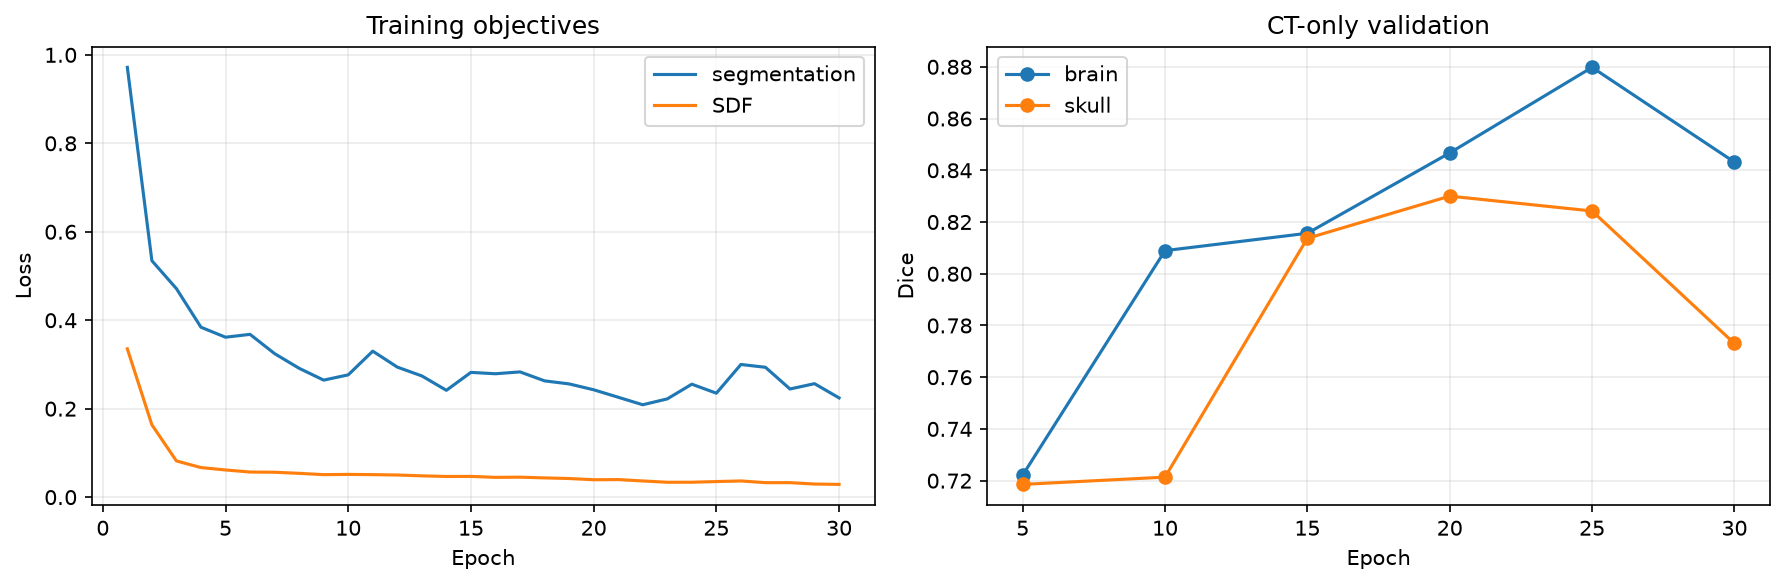

In [12]:
phase1_loaded = json.loads(report_path.read_text(encoding="utf-8"))
phase2_validation = phase2_report["validation"]
comparison_rows = []
for organ in ("brain", "skull"):
    phase1_dice = phase1_loaded["ct_only_result"]["mean_dice"][organ]
    phase2_dice = phase2_validation["mean_dice"][organ]
    comparison_rows.extend([
        {
            "phase": "Phase 1 segmentation-only",
            "organ": organ,
            "dice": phase1_dice,
            "hd95_mm": phase1_loaded["ct_only_result"]["mean_hd95_mm"][organ],
            "sdf_mae_mm_truncated": np.nan,
        },
        {
            "phase": "Phase 2 segmentation+SDF",
            "organ": organ,
            "dice": phase2_dice,
            "hd95_mm": phase2_validation["mean_hd95_mm"][organ],
            "sdf_mae_mm_truncated": phase2_validation["mean_sdf_mae_normalized"][organ] * float(sdf_cfg["max_distance_mm"]),
        },
    ])
phase_comparison = pd.DataFrame(comparison_rows)
phase_comparison.to_csv(PHASE2_ROOT / "phase1_vs_phase2.csv", index=False)
display(phase_comparison.style.format(precision=4, na_rep="â€”"))

deltas = {
    organ: {
        "dice": phase2_validation["mean_dice"][organ] - phase1_loaded["ct_only_result"]["mean_dice"][organ],
        "hd95_mm": phase2_validation["mean_hd95_mm"][organ] - phase1_loaded["ct_only_result"]["mean_hd95_mm"][organ],
    }
    for organ in ("brain", "skull")
}
print("Measured Phase 2 minus Phase 1 deltas:", json.dumps(deltas, indent=2))

history = json.loads((PHASE2_ROOT / "history.json").read_text(encoding="utf-8"))
history_frame = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=150)
axes[0].plot(history_frame["epoch"], history_frame["segmentation_loss"], label="segmentation")
axes[0].plot(history_frame["epoch"], history_frame["sdf_loss"], label="SDF")
axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training objectives")
validated = history_frame.dropna(subset=["validation_macro_dice"])
axes[1].plot(validated["epoch"], validated["validation_brain_dice"], marker="o", label="brain")
axes[1].plot(validated["epoch"], validated["validation_skull_dice"], marker="o", label="skull")
axes[1].set(xlabel="Epoch", ylabel="Dice", title="CT-only validation")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend()
fig.tight_layout()
curves_path = PHASE2_ROOT / "phase2_learning_curves.png"
fig.savefig(curves_path, bbox_inches="tight")
plt.show()

## 11. Phase 2 segmentation and SDF visual evidence

The trained geometry head is visualized independently of segmentation. Absolute SDF error is reported in the
normalized truncated-distance domain; multiplying by 25 gives the corresponding truncated millimetre scale.

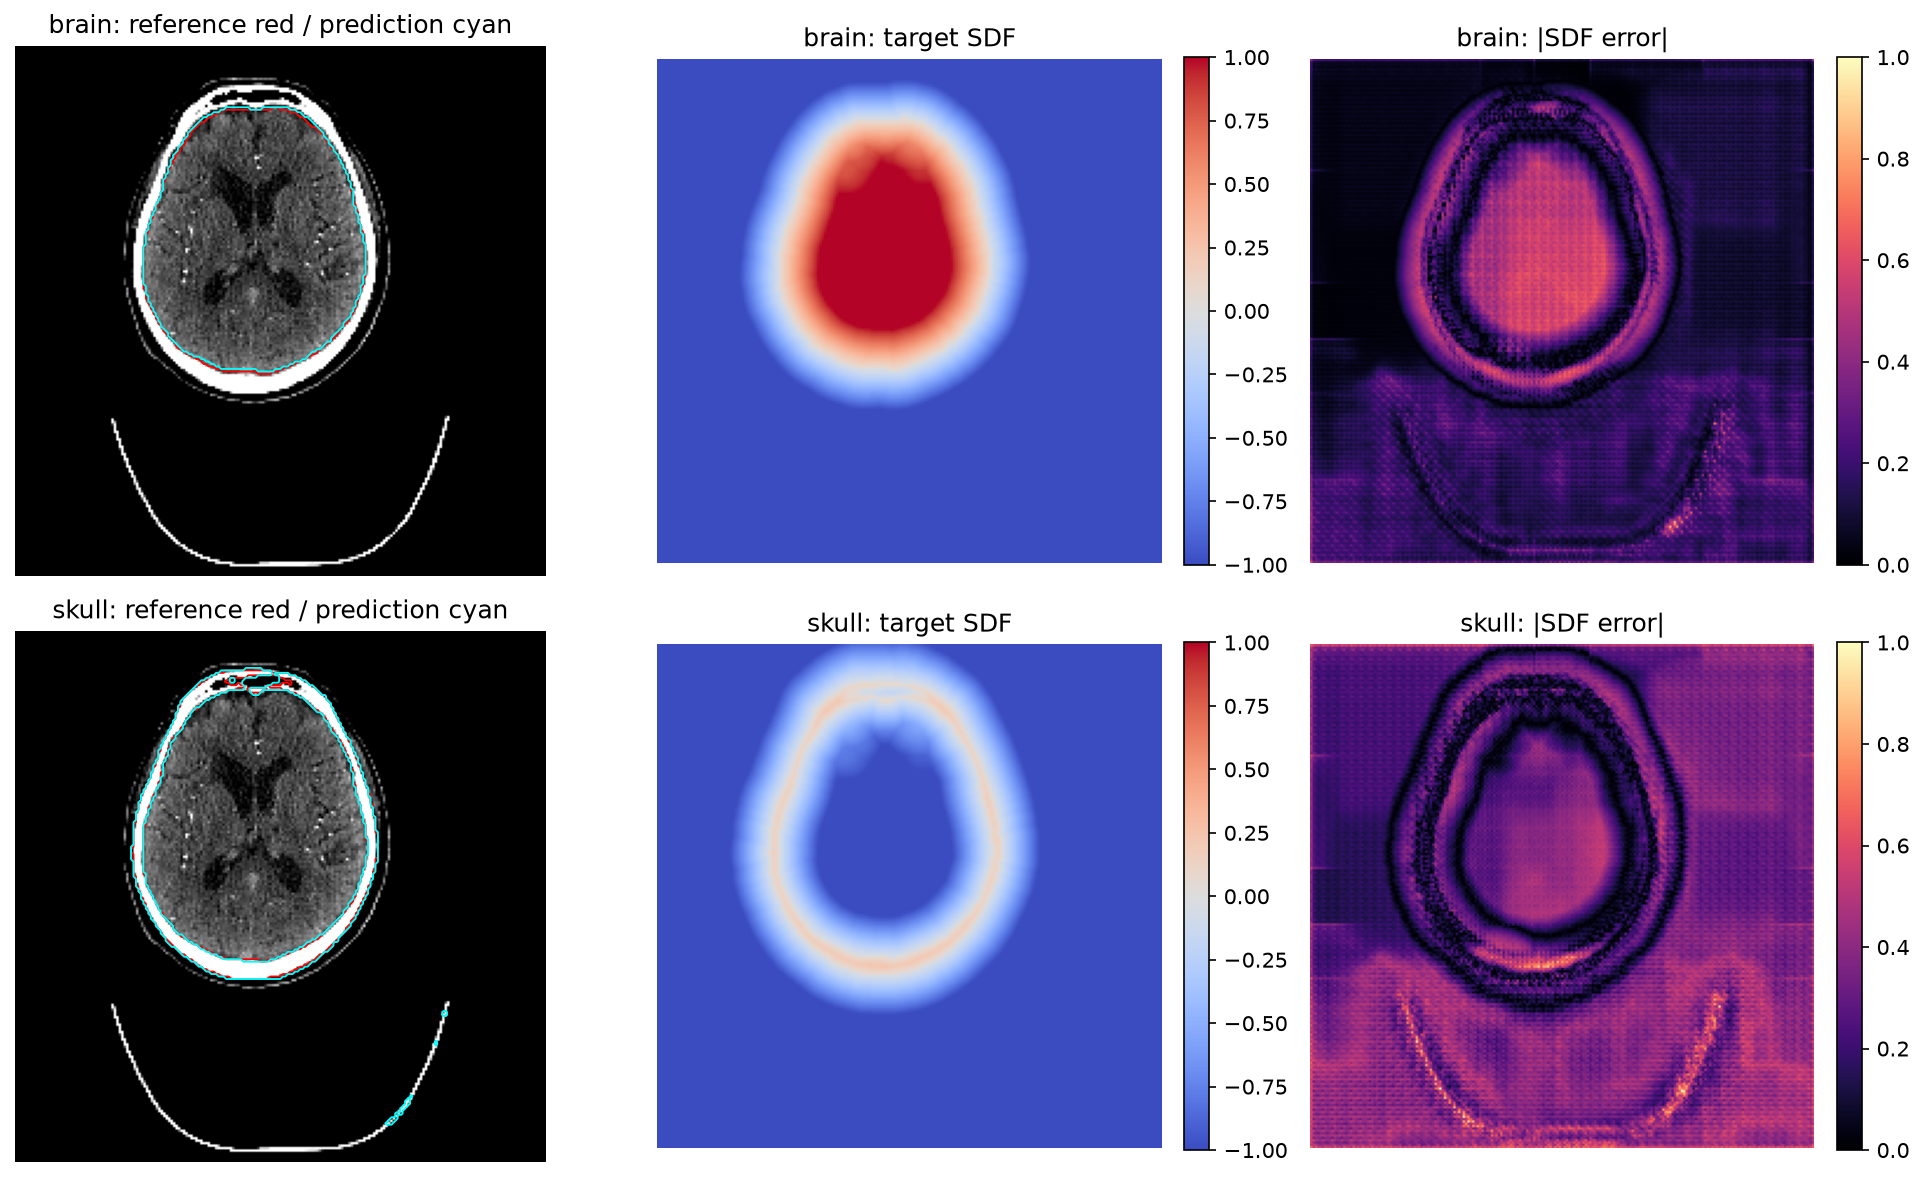

In [13]:
best_phase2 = torch.load(Path(phase2_report["best_checkpoint"]), map_location="cpu", weights_only=True)
phase2_model = build_phase2_model(phase2_config).to(DEVICE)
phase2_model.load_state_dict(best_phase2["model_state"])
phase2_model.eval()
example = next(item for item in phase2_val if item["case_id"] == "s0346")
phase2_prediction, phase2_sdf = predict_multitask(
    phase2_model,
    example,
    device=DEVICE,
    roi=int(data_cfg["roi_size"][0]),
    overlap=float(phase2_config["inference"]["overlap"]),
)
reference = np.load(example["label_path"], mmap_mode="r")
target_sdf = np.load(example["sdf_path"], mmap_mode="r")
image = np.load(example["image_path"], mmap_mode="r")[0]
z = int(np.rint(np.argwhere(reference == 1)[:, 2].mean()))

fig, axes = plt.subplots(2, 3, figsize=(13, 8), dpi=150)
for row, (class_id, organ) in enumerate(((1, "brain"), (2, "skull"))):
    axes[row, 0].imshow(image[:, :, z].T, cmap="gray", origin="lower", vmin=0.35, vmax=0.75)
    axes[row, 0].contour((reference[:, :, z] == class_id).T, levels=[0.5], colors="red", linewidths=0.9)
    axes[row, 0].contour((phase2_prediction[:, :, z] == class_id).T, levels=[0.5], colors="cyan", linewidths=0.9)
    axes[row, 0].set_title(f"{organ}: reference red / prediction cyan")
    target_shown = axes[row, 1].imshow(target_sdf[row, :, :, z].T, cmap="coolwarm", origin="lower", vmin=-1, vmax=1)
    axes[row, 1].set_title(f"{organ}: target SDF")
    error = np.abs(phase2_sdf[row] - target_sdf[row])
    error_shown = axes[row, 2].imshow(error[:, :, z].T, cmap="magma", origin="lower", vmin=0, vmax=1)
    axes[row, 2].set_title(f"{organ}: |SDF error|")
    fig.colorbar(target_shown, ax=axes[row, 1], fraction=0.046, pad=0.04)
    fig.colorbar(error_shown, ax=axes[row, 2], fraction=0.046, pad=0.04)
for axis in axes.flat:
    axis.axis("off")
fig.tight_layout()
phase2_visual_path = PHASE2_ROOT / "phase2_segmentation_sdf_s0346.png"
fig.savefig(phase2_visual_path, bbox_inches="tight")
plt.show()

## 12. Extend the same framework report

Phase 1 remains immutable. The framework-level report now references both phase reports and records the actual
measured change. Passing Phase 2 means that the model, SDF targets, checkpoint, and measurements are valid and
reproducible; it does **not** require an artificial improvement.

In [14]:
phase2_acceptance = {
    "phase1_passed": phase1_loaded["status"] == "passed",
    "official_test_split_unopened": phase2_report["official_test_split_accessed"] is False,
    "frozen_development_counts": len(phase2_train) == 98 and len(phase2_val) == 5,
    "all_crops_ct_only": all(item["crop_selected_without_labels"] for item in phase2_records),
    "all_targets_retained": all(
        np.isclose(item["reference_retention"][organ], 1.0)
        for item in phase2_records for organ in ("brain", "skull")
    ),
    "sdf_sign_and_range_verified": bool(
        np.isfinite(sdf_target).all() and sdf_target.min() >= -1 and sdf_target.max() <= 1
    ),
    "training_completed": phase2_report["completed_epochs"] == int(phase2_config["training"]["epochs"]),
    "best_checkpoint_hash_verified": phase2_sha256_file(Path(phase2_report["best_checkpoint"])) == phase2_report["best_checkpoint_sha256"],
    "validation_metrics_finite": all(
        np.isfinite(phase2_report["validation"]["mean_dice"][organ])
        and np.isfinite(phase2_report["validation"]["mean_hd95_mm"][organ])
        for organ in ("brain", "skull")
    ),
}
phase2_passed = all(phase2_acceptance.values())
phase2_summary = {
    "schema_version": 1,
    "phase": 2,
    "status": "passed" if phase2_passed else "failed",
    "config": str(PHASE2_CONFIG_PATH),
    "config_sha256": sha256_file(PHASE2_CONFIG_PATH),
    "acceptance": phase2_acceptance,
    "model_report": phase2_report,
    "phase1_ct_only_baseline": phase1_loaded["ct_only_result"],
    "measured_deltas": deltas,
    "outputs": {
        "comparison_csv": str(PHASE2_ROOT / "phase1_vs_phase2.csv"),
        "history": str(PHASE2_ROOT / "history.json"),
        "learning_curves": str(curves_path),
        "sdf_target_qa": str(sdf_figure_path),
        "segmentation_sdf_visual": str(phase2_visual_path),
    },
    "official_test_split_accessed": False,
    "next_phase": "brain-skull anatomical relational constraints and violation maps",
}
phase2_report_path = PHASE2_ROOT / "phase2_report.json"
phase2_report_path.write_text(json.dumps(phase2_summary, indent=2) + "\n", encoding="utf-8")
framework_report = {
    "schema_version": 1,
    "framework": "An Anatomy-Aware Self-Correcting and Geometry-Adaptive Framework",
    "completed_phases": [1, 2] if phase2_passed else [1],
    "phase1_report": str(report_path),
    "phase1_status": phase1_loaded["status"],
    "phase2_report": str(phase2_report_path),
    "phase2_status": phase2_summary["status"],
    "official_test_split_accessed": False,
}
framework_report_path = OUTPUT_ROOT.parent / "framework_report.json"
framework_report_path.write_text(json.dumps(framework_report, indent=2) + "\n", encoding="utf-8")
display(pd.DataFrame(phase2_acceptance.items(), columns=["check", "value"]))
print("Phase 2:", phase2_summary["status"])
print("Combined framework report:", framework_report_path)
if not phase2_passed:
    raise RuntimeError("Phase 2 acceptance failed; do not proceed to Phase 3")

del phase2_model
torch.cuda.empty_cache()

,check,value
0,phase1_passed,True
1,official_test_split_unopened,True
2,frozen_development_counts,True
3,all_crops_ct_only,True
4,all_targets_retained,True
5,sdf_sign_and_range_verified,True
6,training_completed,True
7,best_checkpoint_hash_verified,True
8,validation_metrics_finite,True


Phase 2: passed
Combined framework report: F:\csstdy\outputs\anatomy_aware_framework\framework_report.json


# Phase 3 â€” Relational anatomy and non-destructive quality control

Phase 3 adds two deliberately separate mechanisms. During fine-tuning, a differentiable relational loss
penalizes brain probability outside a skull-derived enclosure, skull probability inside the deep brain core,
class ambiguity, and segmentation/SDF sign disagreement. After inference, an independent quality-control
map `V(x)` localizes possible anatomical violations but **never edits the prediction**.

The Phase 2 best checkpoint initializes training. The same five CT-only validation cases select the Phase 3
checkpoint, so all results remain development estimates. The official test split stays unopened.

In [15]:
from src.anatomy.targets import prepare_anatomy_target_cache
from src.anatomy.violations import fit_surface_distance_reference
from src.training.anatomy_phase3 import evaluate_anatomy_qc, train_phase3

PHASE3_CONFIG_PATH = PROJECT_ROOT / "configs" / "anatomy_aware_phase3_v1.yaml"
phase3_config = yaml.safe_load(PHASE3_CONFIG_PATH.read_text(encoding="utf-8"))
PHASE3_ROOT = PROJECT_ROOT / phase3_config["outputs"]["root"]
PHASE3_ROOT.mkdir(parents=True, exist_ok=True)
if not phase2_passed:
    raise RuntimeError("Phase 3 is blocked because Phase 2 did not pass")
if phase3_config["locks"]["official_test_locked"] is not True:
    raise RuntimeError("Phase 3 configuration must keep the official test split locked")
if phase2_sha256_file(PHASE2_CONFIG_PATH) != phase2_summary["config_sha256"]:
    raise RuntimeError("The frozen Phase 2 configuration changed")
if phase2_sha256_file(Path(phase2_report["best_checkpoint"])) != phase2_report["best_checkpoint_sha256"]:
    raise RuntimeError("The frozen Phase 2 checkpoint changed")
print("Phase 3 config:", PHASE3_CONFIG_PATH)

Phase 3 config: F:\csstdy\configs\anatomy_aware_phase3_v1.yaml


## 13. Build relational targets and a training-only distance reference

The skull enclosure is the axial convex hull of the reference skull. The deep-brain core is defined by a
physical 3 mm distance from the brain boundary. These are training targets, not an atlas or template.
Surface-distance plausibility limits are fitted exclusively from the 98 training labels and then frozen.

In [16]:
def anatomy_cache_progress(index, total, case_id):
    if index == 1 or index % 20 == 0 or index == total:
        print(f"Anatomy targets {index}/{total}: {case_id}", flush=True)

phase3_records = prepare_anatomy_target_cache(
    phase2_records,
    brain_core_distance_mm=float(phase3_config["targets"]["brain_core_distance_mm"]),
    progress=anatomy_cache_progress,
)
phase3_train = [item for item in phase3_records if item["split"] == "train"]
phase3_val = [item for item in phase3_records if item["split"] == "val"]
retention = [
    item["anatomy_target_metrics"]["brain_enclosure_retention"] for item in phase3_records
]
assert len(phase3_train) == 98 and len(phase3_val) == 5
assert min(retention) >= 0.95

qc_cfg = phase3_config["quality_control"]
distance_reference = fit_surface_distance_reference(
    phase3_train,
    percentiles=tuple(float(value) for value in qc_cfg["distance_reference_percentiles"]),
    samples_per_case=int(qc_cfg["distance_samples_per_case"]),
    seed=int(phase3_config["training"]["random_seed"]),
)
distance_reference_path = PHASE3_ROOT / "anatomy_distance_reference.json"
distance_reference_path.write_text(json.dumps(distance_reference, indent=2) + "\n", encoding="utf-8")
target_audit = {
    "cases": len(phase3_records),
    "minimum_brain_enclosure_retention": float(min(retention)),
    "mean_brain_enclosure_retention": float(np.mean(retention)),
    "training_only_distance_reference": distance_reference,
}
(PHASE3_ROOT / "anatomy_target_audit.json").write_text(
    json.dumps(target_audit, indent=2) + "\n", encoding="utf-8"
)
display(pd.DataFrame([target_audit | {
    "distance_lower_mm": distance_reference["lower_mm"],
    "distance_upper_mm": distance_reference["upper_mm"],
}]).drop(columns="training_only_distance_reference"))

Anatomy targets 1/103: s0101


Anatomy targets 20/103: s0478


Anatomy targets 40/103: s0706


Anatomy targets 60/103: s0993


Anatomy targets 80/103: s1154


Anatomy targets 100/103: s0792


Anatomy targets 103/103: s1260


,cases,minimum_brain_enclosure_retention,mean_brain_enclosure_retention,distance_lower_mm,distance_upper_mm
0,103,0.997874,0.999894,1.5,34.630188


## 14. Inspect the anatomy targets

This overlay checks that the skull-derived enclosure contains the brain while the eroded core remains safely
inside it. It is saved as evidence before fine-tuning starts.

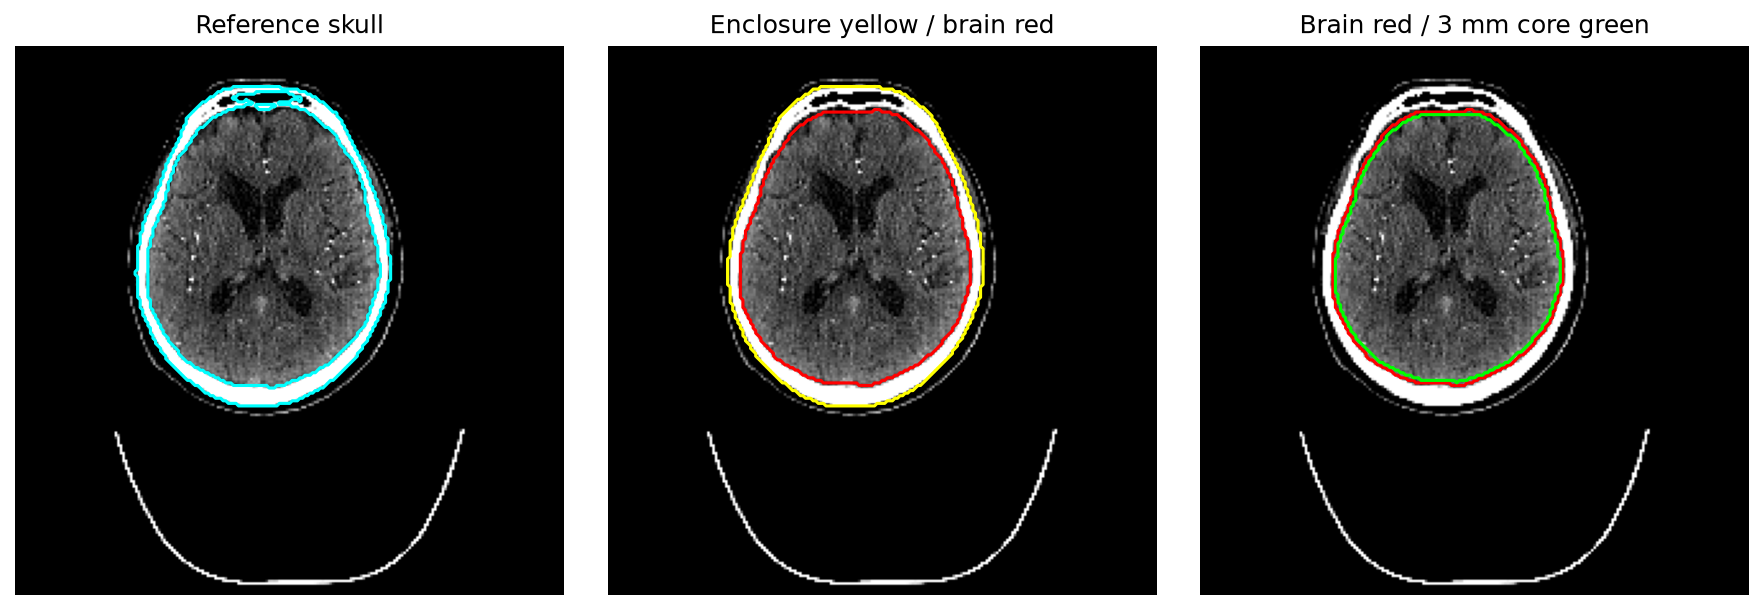

In [17]:
anatomy_example = next(item for item in phase3_val if item["case_id"] == "s0346")
anatomy_image = np.load(anatomy_example["image_path"], mmap_mode="r")[0]
anatomy_label = np.load(anatomy_example["label_path"], mmap_mode="r")
anatomy_enclosure = np.load(anatomy_example["enclosure_path"], mmap_mode="r")
anatomy_core = np.load(anatomy_example["brain_core_path"], mmap_mode="r")
z_anatomy = int(np.rint(np.argwhere(anatomy_label == 1)[:, 2].mean()))
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=150)
for axis in axes:
    axis.imshow(anatomy_image[:, :, z_anatomy].T, cmap="gray", origin="lower", vmin=0.35, vmax=0.75)
    axis.axis("off")
axes[0].contour((anatomy_label[:, :, z_anatomy] == 2).T, [0.5], colors="cyan")
axes[0].set_title("Reference skull")
axes[1].contour(anatomy_enclosure[:, :, z_anatomy].T, [0.5], colors="yellow")
axes[1].contour((anatomy_label[:, :, z_anatomy] == 1).T, [0.5], colors="red")
axes[1].set_title("Enclosure yellow / brain red")
axes[2].contour((anatomy_label[:, :, z_anatomy] == 1).T, [0.5], colors="red")
axes[2].contour(anatomy_core[:, :, z_anatomy].T, [0.5], colors="lime")
axes[2].set_title("Brain red / 3 mm core green")
fig.tight_layout()
anatomy_targets_path = PHASE3_ROOT / "anatomy_targets_s0346.png"
fig.savefig(anatomy_targets_path, bbox_inches="tight")
plt.show()

## 15. Fine-tune or resume the anatomy-aware model

The original Phase 2 segmentation and SDF objective remains active. A scheduled anatomy weight of 0.02,
0.05, and 0.10 is added over 15 epochs. `last.pt` is resumable; `best.pt` is still selected only by validation
macro Dice, rather than by the new constraint itself.

In [18]:
phase3_report = train_phase3(
    phase3_records,
    phase2_config,
    phase3_config,
    PHASE3_ROOT,
    phase2_checkpoint=Path(phase2_report["best_checkpoint"]),
    phase3_config_sha256=phase2_sha256_file(PHASE3_CONFIG_PATH),
    progress=lambda message: print(message, flush=True),
)
assert phase3_report["official_test_split_accessed"] is False
print("Selected Phase 3 epoch:", phase3_report["selected_epoch"])
display(pd.DataFrame([
    {
        "organ": organ,
        "Phase 2 Dice": phase2_report["validation"]["mean_dice"][organ],
        "Phase 3 Dice": phase3_report["validation"]["mean_dice"][organ],
        "Phase 2 HD95 (mm)": phase2_report["validation"]["mean_hd95_mm"][organ],
        "Phase 3 HD95 (mm)": phase3_report["validation"]["mean_hd95_mm"][organ],
    }
    for organ in ("brain", "skull")
]).style.format(precision=4))

Selected Phase 3 epoch: 10


,organ,Phase 2 Dice,Phase 3 Dice,Phase 2 HD95 (mm),Phase 3 HD95 (mm)
0,brain,0.8798,0.9136,176.2267,130.4905
1,skull,0.8243,0.8919,162.0764,129.7477


## 16. Phase 2 versus Phase 3 learning and segmentation metrics

Both checkpoints are scored on identical CT-only validation volumes. Any negative delta is retained; Phase 3
acceptance checks implementation integrity and reproducibility rather than forcing a favorable conclusion.

,organ,phase2_dice,phase3_dice,dice_delta,phase2_hd95_mm,phase3_hd95_mm,hd95_delta_mm
0,brain,0.8798,0.9136,0.0338,176.2267,130.4905,-45.7362
1,skull,0.8243,0.8919,0.0677,162.0764,129.7477,-32.3287


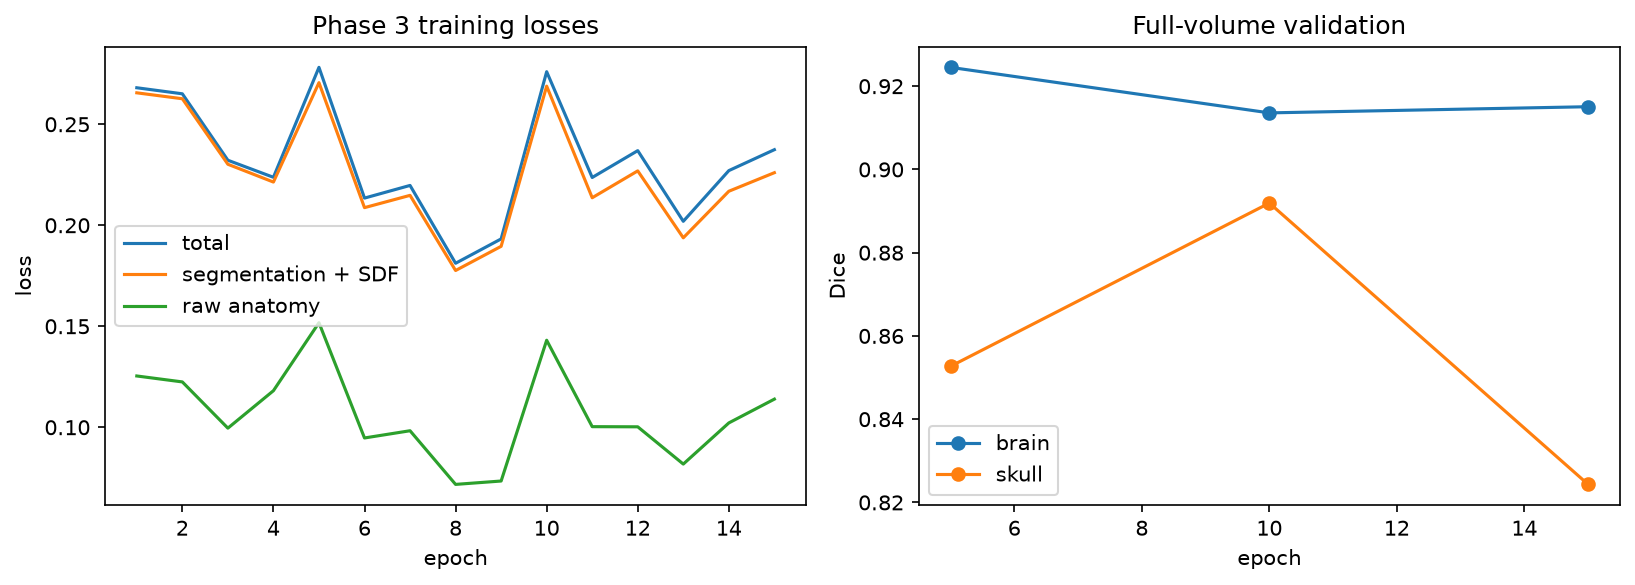

In [19]:
phase3_comparison = pd.DataFrame([
    {
        "organ": organ,
        "phase2_dice": phase2_report["validation"]["mean_dice"][organ],
        "phase3_dice": phase3_report["validation"]["mean_dice"][organ],
        "dice_delta": phase3_report["validation"]["mean_dice"][organ] - phase2_report["validation"]["mean_dice"][organ],
        "phase2_hd95_mm": phase2_report["validation"]["mean_hd95_mm"][organ],
        "phase3_hd95_mm": phase3_report["validation"]["mean_hd95_mm"][organ],
        "hd95_delta_mm": phase3_report["validation"]["mean_hd95_mm"][organ] - phase2_report["validation"]["mean_hd95_mm"][organ],
    }
    for organ in ("brain", "skull")
])
phase3_comparison_path = PHASE3_ROOT / "phase2_vs_phase3.csv"
phase3_comparison.to_csv(phase3_comparison_path, index=False)
display(phase3_comparison.style.format(precision=4))

phase3_history = pd.DataFrame(json.loads((PHASE3_ROOT / "history.json").read_text(encoding="utf-8")))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=150)
axes[0].plot(phase3_history["epoch"], phase3_history["total_loss"], label="total")
axes[0].plot(phase3_history["epoch"], phase3_history["base_multitask_loss"], label="segmentation + SDF")
axes[0].plot(phase3_history["epoch"], phase3_history["anatomy_loss"], label="raw anatomy")
axes[0].set(xlabel="epoch", ylabel="loss", title="Phase 3 training losses")
axes[0].legend()
validated = phase3_history.dropna(subset=["validation_macro_dice"])
axes[1].plot(validated["epoch"], validated["validation_brain_dice"], marker="o", label="brain")
axes[1].plot(validated["epoch"], validated["validation_skull_dice"], marker="o", label="skull")
axes[1].set(xlabel="epoch", ylabel="Dice", title="Full-volume validation")
axes[1].legend()
fig.tight_layout()
phase3_curves_path = PHASE3_ROOT / "phase3_learning_curves.png"
fig.savefig(phase3_curves_path, bbox_inches="tight")
plt.show()

## 17. Independent anatomical violation maps

The Phase 2 and Phase 3 predictions are each passed unchanged into the same QC calculation. `V(x)` combines
skull-enclosure violations, probability ambiguity, major disconnected components, implausible brain-to-skull
surface distance, and SDF sign disagreement. The maps are saved as NIfTI in the cropped CT geometry.

,metric,phase2,phase3,delta
0,brain_outside_enclosure_fraction,0.041854,0.052245,0.010391
1,surface_distance_mean_mm,7.977327,6.632206,-1.345122
2,surface_distance_max_mm,79.024941,62.283090,-16.741851
3,probability_ambiguity_mean,0.002201,0.001698,-0.000502
4,sdf_sign_disagreement_fraction,0.029447,0.025327,-0.004121
5,violation_mean,0.006394,0.004748,-0.001646
6,violation_nonzero_fraction,0.999998,0.999997,-0.000001
7,violation_above_0_05_fraction,0.033296,0.027092,-0.006204
8,disconnected_major_components_brain,2.400000,1.200000,-1.200000
9,disconnected_major_components_skull,4.400000,1.800000,-2.600000


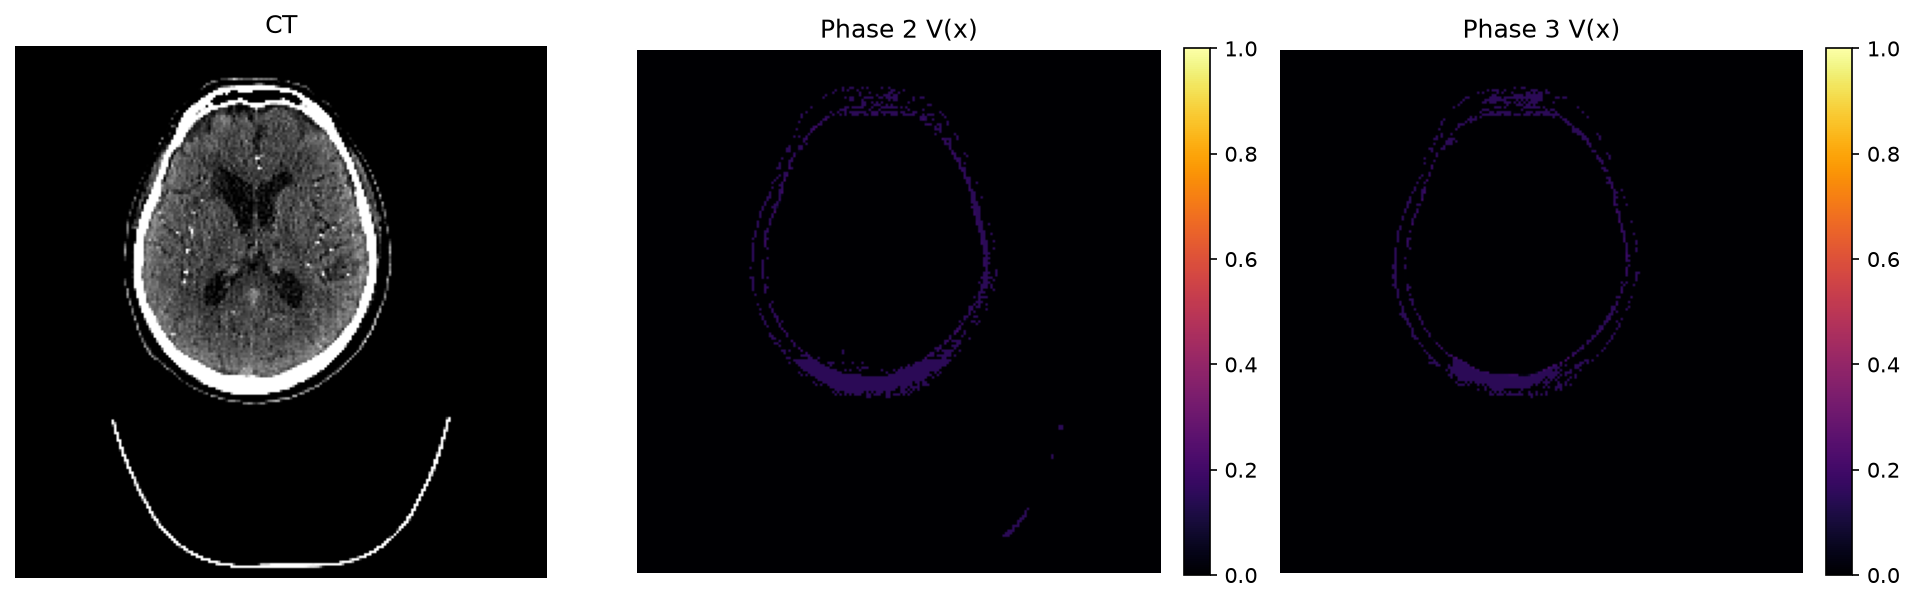

In [20]:
phase2_qc_model = build_phase2_model(phase2_config).to(DEVICE)
phase2_qc_checkpoint = torch.load(Path(phase2_report["best_checkpoint"]), map_location="cpu", weights_only=True)
phase2_qc_model.load_state_dict(phase2_qc_checkpoint["model_state"])
phase2_qc = evaluate_anatomy_qc(
    phase2_qc_model,
    phase3_val,
    distance_reference,
    qc_cfg,
    device=DEVICE,
    roi=int(data_cfg["roi_size"][0]),
    overlap=float(phase2_config["inference"]["overlap"]),
    output_root=PHASE3_ROOT / "qc_phase2",
)
del phase2_qc_model
torch.cuda.empty_cache()

phase3_qc_model = build_phase2_model(phase2_config).to(DEVICE)
phase3_qc_checkpoint = torch.load(Path(phase3_report["best_checkpoint"]), map_location="cpu", weights_only=True)
phase3_qc_model.load_state_dict(phase3_qc_checkpoint["model_state"])
phase3_qc = evaluate_anatomy_qc(
    phase3_qc_model,
    phase3_val,
    distance_reference,
    qc_cfg,
    device=DEVICE,
    roi=int(data_cfg["roi_size"][0]),
    overlap=float(phase2_config["inference"]["overlap"]),
    output_root=PHASE3_ROOT / "qc_phase3",
)
del phase3_qc_model
torch.cuda.empty_cache()

qc_rows = []
for metric, phase2_value in phase2_qc["means"].items():
    phase3_value = phase3_qc["means"][metric]
    qc_rows.append({
        "metric": metric,
        "phase2": phase2_value,
        "phase3": phase3_value,
        "delta": None if phase2_value is None or phase3_value is None else phase3_value - phase2_value,
    })
qc_comparison = pd.DataFrame(qc_rows)
qc_comparison_path = PHASE3_ROOT / "phase2_vs_phase3_qc.csv"
qc_comparison.to_csv(qc_comparison_path, index=False)
display(qc_comparison.style.format(precision=6))

phase2_v = np.asarray(nib.load(str(PHASE3_ROOT / "qc_phase2" / "s0346" / "anatomical_violation.nii.gz")).dataobj)
phase3_v = np.asarray(nib.load(str(PHASE3_ROOT / "qc_phase3" / "s0346" / "anatomical_violation.nii.gz")).dataobj)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=150)
axes[0].imshow(anatomy_image[:, :, z_anatomy].T, cmap="gray", origin="lower", vmin=0.35, vmax=0.75)
axes[0].set_title("CT")
for axis, values, title in ((axes[1], phase2_v, "Phase 2 V(x)"), (axes[2], phase3_v, "Phase 3 V(x)")):
    shown = axis.imshow(values[:, :, z_anatomy].T, cmap="inferno", origin="lower", vmin=0, vmax=1)
    axis.set_title(title)
    fig.colorbar(shown, ax=axis, fraction=0.046, pad=0.04)
for axis in axes:
    axis.axis("off")
fig.tight_layout()
violation_visual_path = PHASE3_ROOT / "phase2_vs_phase3_violation_s0346.png"
fig.savefig(violation_visual_path, bbox_inches="tight")
plt.show()

## 18. Extend the framework report through Phase 3

Phase 3 passes when its provenance, target construction, training, checkpoint, metrics, and non-destructive QC
outputs are complete and finite. A score improvement is an observed result, not an acceptance prerequisite.

In [21]:
qc_scalars = [value for value in phase3_qc["means"].values() if value is not None]
phase3_acceptance = {
    "phase2_passed": phase2_summary["status"] == "passed",
    "official_test_split_unopened": phase3_report["official_test_split_accessed"] is False,
    "frozen_development_counts": len(phase3_train) == 98 and len(phase3_val) == 5,
    "phase2_initial_checkpoint_hash_verified": phase3_report["initial_checkpoint_sha256"] == phase2_report["best_checkpoint_sha256"],
    "anatomy_targets_retain_brain": min(retention) >= 0.95,
    "distance_reference_training_only": distance_reference["training_cases"] == 98,
    "training_completed": phase3_report["completed_epochs"] == int(phase3_config["training"]["epochs"]),
    "best_checkpoint_hash_verified": phase2_sha256_file(Path(phase3_report["best_checkpoint"])) == phase3_report["best_checkpoint_sha256"],
    "validation_metrics_finite": all(
        np.isfinite(phase3_report["validation"]["mean_dice"][organ])
        and np.isfinite(phase3_report["validation"]["mean_hd95_mm"][organ])
        for organ in ("brain", "skull")
    ),
    "qc_metrics_finite": all(np.isfinite(value) for value in qc_scalars),
    "qc_did_not_modify_predictions": phase2_qc["prediction_was_modified"] is False and phase3_qc["prediction_was_modified"] is False,
    "violation_nifti_saved_for_all_validation_cases": all(
        (PHASE3_ROOT / variant / item["case_id"] / "anatomical_violation.nii.gz").is_file()
        for variant in ("qc_phase2", "qc_phase3") for item in phase3_val
    ),
}
phase3_passed = all(phase3_acceptance.values())
phase3_summary = {
    "schema_version": 1,
    "phase": 3,
    "status": "passed" if phase3_passed else "failed",
    "config": str(PHASE3_CONFIG_PATH),
    "config_sha256": phase2_sha256_file(PHASE3_CONFIG_PATH),
    "acceptance": phase3_acceptance,
    "model_report": phase3_report,
    "phase2_model_report": phase2_report,
    "segmentation_comparison": phase3_comparison.to_dict(orient="records"),
    "quality_control": {"phase2": phase2_qc, "phase3": phase3_qc},
    "distance_reference": distance_reference,
    "outputs": {
        "comparison_csv": str(phase3_comparison_path),
        "qc_comparison_csv": str(qc_comparison_path),
        "history": str(PHASE3_ROOT / "history.json"),
        "learning_curves": str(phase3_curves_path),
        "target_visual": str(anatomy_targets_path),
        "violation_visual": str(violation_visual_path),
    },
    "official_test_split_accessed": False,
    "next_phase": "uncertainty estimation and selective rescue",
}
phase3_report_path = PHASE3_ROOT / "phase3_report.json"
phase3_report_path.write_text(json.dumps(phase3_summary, indent=2) + "\n", encoding="utf-8")
framework_report.update({
    "completed_phases": [1, 2, 3] if phase3_passed else [1, 2],
    "phase3_report": str(phase3_report_path),
    "phase3_status": phase3_summary["status"],
    "official_test_split_accessed": False,
})
framework_report_path.write_text(json.dumps(framework_report, indent=2) + "\n", encoding="utf-8")
display(pd.DataFrame(phase3_acceptance.items(), columns=["check", "value"]))
print("Phase 3:", phase3_summary["status"])
print("Combined framework report:", framework_report_path)
if not phase3_passed:
    raise RuntimeError("Phase 3 acceptance failed; do not proceed to Phase 4")

,check,value
0,phase2_passed,True
1,official_test_split_unopened,True
2,frozen_development_counts,True
3,phase2_initial_checkpoint_hash_verified,True
4,anatomy_targets_retain_brain,True
5,distance_reference_training_only,True
6,training_completed,True
7,best_checkpoint_hash_verified,True
8,validation_metrics_finite,True
9,qc_metrics_finite,True


Phase 3: passed
Combined framework report: F:\csstdy\outputs\anatomy_aware_framework\framework_report.json


## Phase boundary

Phases 1â€“3 are complete in this notebook and the same framework report. Phase 4 may consume the saved
uncertainty and violation evidence for selective rescue, but it must keep correction separate from this
Phase 3 detector and must not tune on the official test split.